# 01 · Análisis exploratorio del PM2.5 (Sesión 1)

Objetivo: decidir qué estaciones y periodos sirven para entrenar el modelo de la Parte 1.

Requisito previo: haber corrido `python scripts/download_siata.py` y `python -m src.data process`, que dejan los archivos en `data/processed/`.

Preguntas que este notebook debe responder:
1. Qué estaciones tienen cobertura suficiente.
2. Si hay periodos con unidades erróneas que deban excluirse.
3. Cómo se distribuye el PM2.5 diario frente al límite de 37 µg/m³ (Res. 2254 de 2017, Art. 2).
4. Qué estacionalidad hay, para elegir variables del modelo.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import config as cfg, ica

PROC = Path(os.environ.get("EDA_DATA", cfg.DATA_PROCESSED))
horario = pd.read_csv(PROC / "pm25_horario.csv", parse_dates=["fecha"])
diario = pd.read_csv(PROC / "pm25_diario.csv", parse_dates=["fecha"])
unidades = pd.read_csv(PROC / "reporte_unidades.csv")
estaciones = pd.read_csv(PROC / "estaciones.csv")
print(f"{horario['estacion'].nunique()} estaciones, {len(horario):,} registros horarios, "
      f"{len(diario):,} estación-día")

30 estaciones, 1,443,970 registros horarios, 62,593 estación-día


## 1. Cobertura por estación

Un día cuenta como válido si tiene al menos 18 de 24 horas (`MIN_FRACCION_HORAS = 0.75` en `src/config.py`).

In [2]:
cob = (diario.groupby("estacion")
       .agg(desde=("fecha", "min"), hasta=("fecha", "max"),
            dias=("fecha", "size"), dias_validos=("valido", "sum"))
       .assign(pct_valido=lambda t: (100 * t["dias_validos"] / t["dias"]).round(1))
       .sort_values("dias_validos", ascending=False))
cob

,desde,hasta,dias,dias_validos,pct_valido
estacion,,,,,
COP-CVID,2019-01-02,2026-09-30,2814,2775,98.6
EST-HOSP,2019-01-01,2026-09-30,2810,2768,98.5
SAB-RAME,2019-01-01,2026-09-30,2810,2767,98.5
ENV-HOSP,2019-01-01,2026-09-30,2809,2764,98.4
MED-VILL,2019-01-01,2026-09-30,2811,2759,98.2
MED-BEME,2019-01-01,2026-09-30,2812,2756,98.0
ITA-CJUS,2019-01-01,2026-09-30,2810,2746,97.7
MED-ARAN,2019-01-01,2026-09-30,2815,2744,97.5
CAL-JOAR,2019-01-01,2026-09-30,2805,2736,97.5


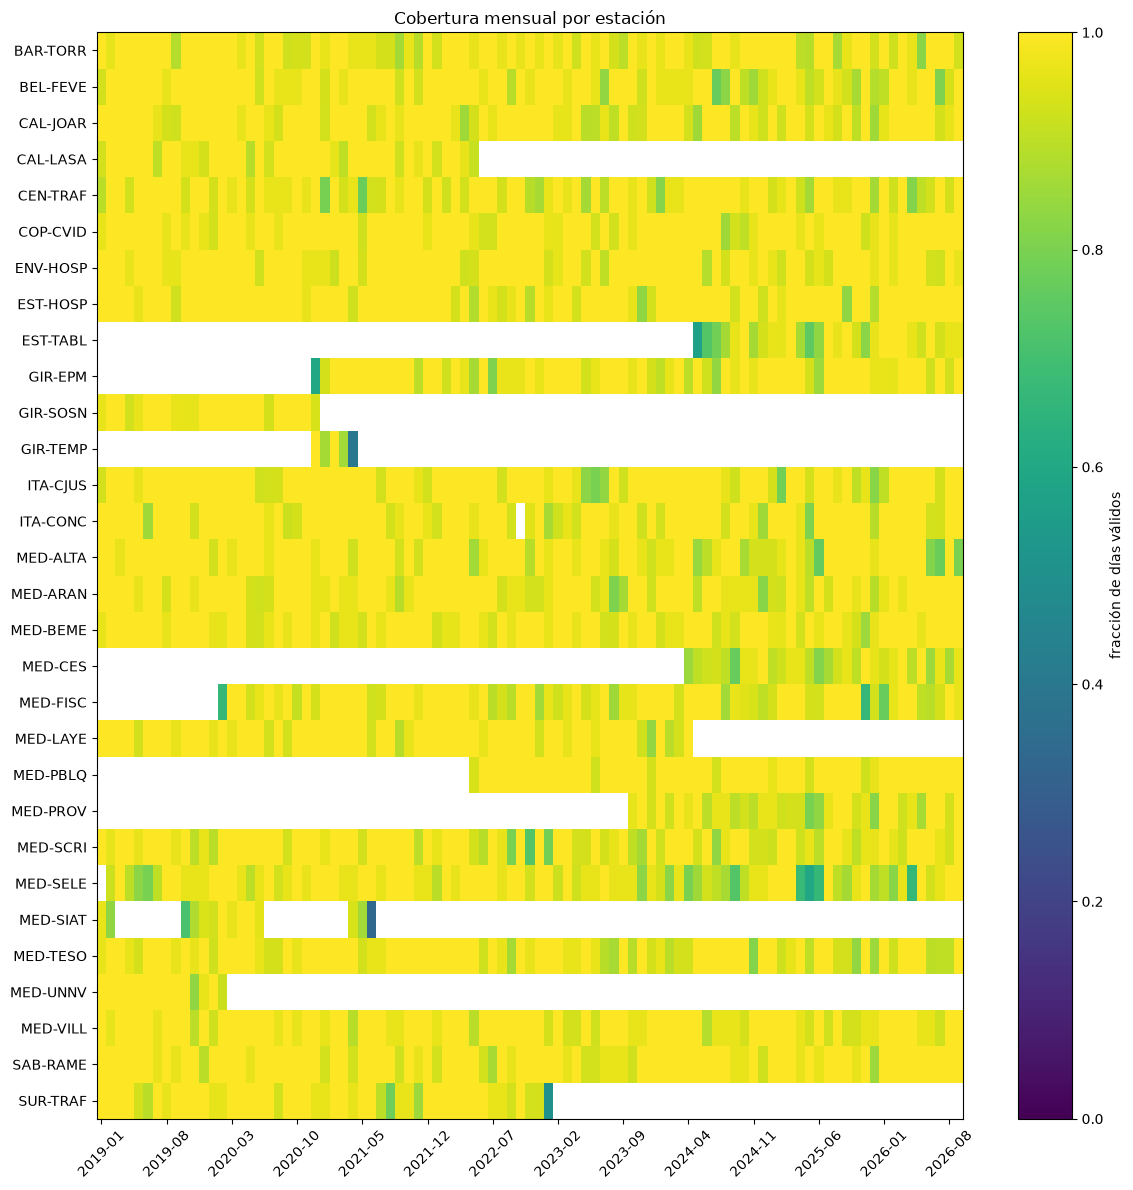

In [3]:
# Porcentaje de días válidos por estación y mes
mapa = (diario.assign(mes=diario["fecha"].dt.to_period("M"))
        .pivot_table(index="estacion", columns="mes", values="valido", aggfunc="mean"))
fig, ax = plt.subplots(figsize=(12, 0.35 * len(mapa) + 1.5))
im = ax.imshow(mapa.values, aspect="auto", vmin=0, vmax=1, cmap="viridis")
ax.set_yticks(range(len(mapa)), mapa.index)
paso = max(1, len(mapa.columns) // 12)
ax.set_xticks(range(0, len(mapa.columns), paso), [str(p) for p in mapa.columns[::paso]], rotation=45)
fig.colorbar(im, ax=ax, label="fracción de días válidos")
ax.set_title("Cobertura mensual por estación")
plt.tight_layout(); plt.show()

## 2. Revisión de unidades

Marca estación-año con mediana horaria mayor a `MEDIANA_SOSPECHOSA` (100 µg/m³, heurística). El README de BRUMA reporta este problema en 14 estaciones entre 2020 y 2023; aquí se verifica con tus datos.

Empty DataFrame
Columns: [estacion, anio, n, mediana, p99, sospechoso]
Index: []


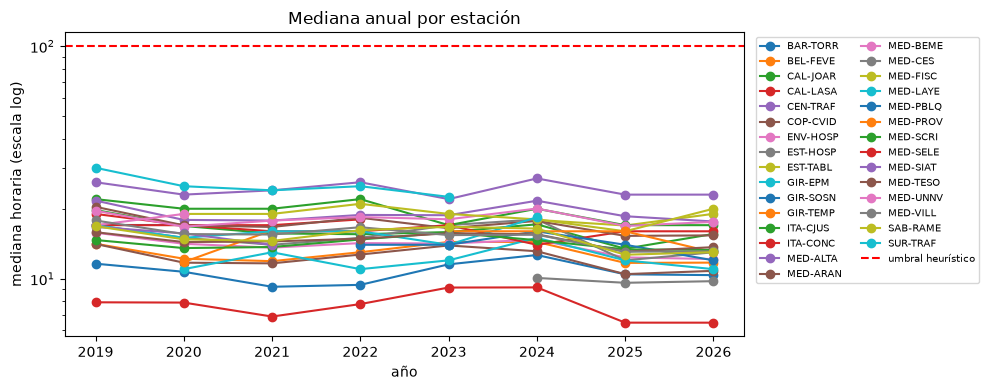

In [4]:
print(unidades[unidades["sospechoso"]].to_string(index=False) or "Sin estación-año sospechosos")
piv = unidades.pivot(index="estacion", columns="anio", values="mediana")
fig, ax = plt.subplots(figsize=(10, 4))
for est, fila in piv.iterrows():
    ax.plot(fila.index, fila.values, marker="o", label=est)
ax.axhline(cfg.MEDIANA_SOSPECHOSA, color="red", ls="--", label="umbral heurístico")
ax.set_yscale("log"); ax.set_ylabel("mediana horaria (escala log)"); ax.set_xlabel("año")
ax.set_title("Mediana anual por estación")
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [5]:
# Excluir los periodos sospechosos para el resto del análisis
malos = set(map(tuple, unidades.loc[unidades["sospechoso"], ["estacion", "anio"]].values))
dv = diario[diario["valido"]].copy()
dv["anio"] = dv["fecha"].dt.year
dv = dv[[ (e, a) not in malos for e, a in zip(dv["estacion"], dv["anio"]) ]]
print(f"Días válidos tras excluir unidades sospechosas: {len(dv):,} de {len(diario):,}")

Días válidos tras excluir unidades sospechosas: 60,902 de 62,593


## 3. PM2.5 diario frente al límite de 37 µg/m³

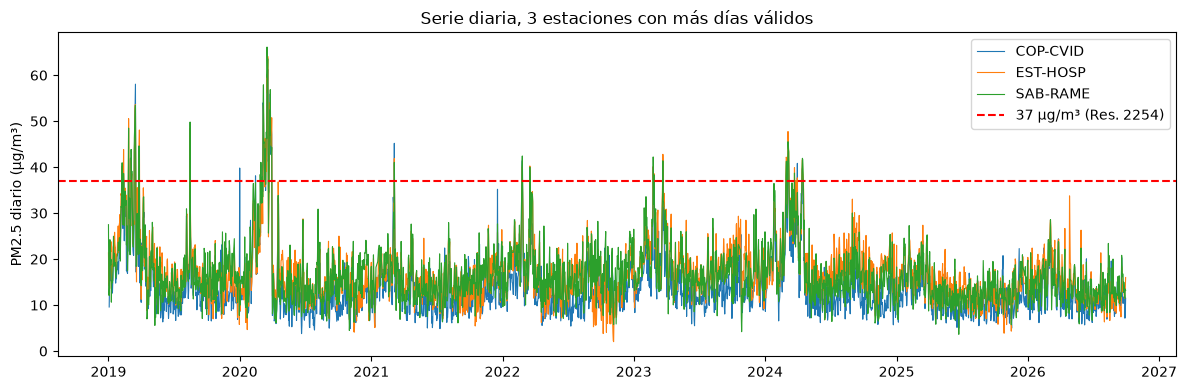

In [6]:
top = cob.index[:3]
fig, ax = plt.subplots(figsize=(12, 4))
for est in top:
    s = dv[dv["estacion"] == est].set_index("fecha")["pm25"]
    ax.plot(s.index, s.values, lw=0.8, label=est)
ax.axhline(cfg.LIMITE_PM25_24H, color="red", ls="--", label="37 µg/m³ (Res. 2254)")
ax.set_ylabel("PM2.5 diario (µg/m³)"); ax.set_title("Serie diaria, 3 estaciones con más días válidos")
ax.legend(); plt.tight_layout(); plt.show()

In [7]:
exced = (dv.assign(excede=dv["pm25"] > cfg.LIMITE_PM25_24H)
         .groupby("estacion")["excede"].agg(dias="size", dias_sobre_37="sum"))
exced["pct"] = (100 * exced["dias_sobre_37"] / exced["dias"]).round(2)
exced.sort_values("pct", ascending=False)

,dias,dias_sobre_37,pct
estacion,,,
SUR-TRAF,1374,177,12.88
MED-SIAT,301,25,8.31
CEN-TRAF,2701,200,7.40
GIR-SOSN,702,49,6.98
CAL-LASA,1192,69,5.79
ITA-CJUS,2746,127,4.62
MED-UNNV,413,15,3.63
MED-ARAN,2744,87,3.17
MED-LAYE,1878,58,3.09


## 4. Estacionalidad

Sirve para decidir si incluir mes y día de la semana como variables.

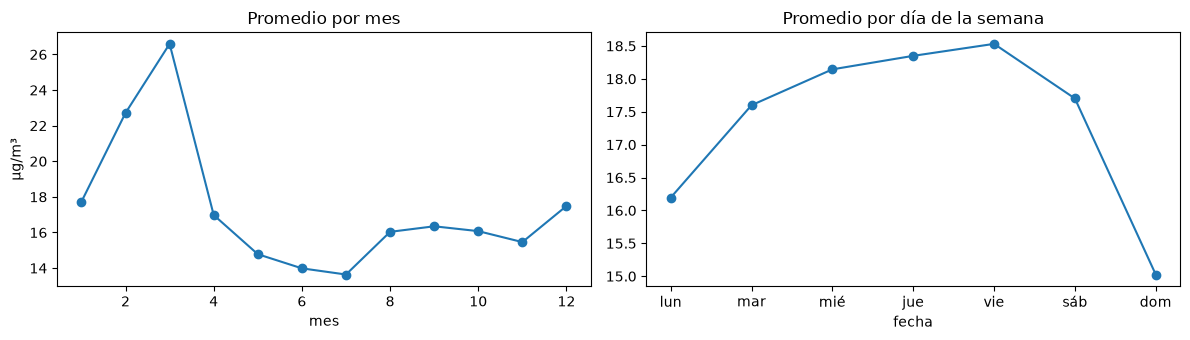

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
dv.groupby(dv["fecha"].dt.month)["pm25"].mean().plot(ax=axes[0], marker="o")
axes[0].set_title("Promedio por mes"); axes[0].set_xlabel("mes"); axes[0].set_ylabel("µg/m³")
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
dv.groupby(dv["fecha"].dt.day_of_week)["pm25"].mean().plot(ax=axes[1], marker="o")
axes[1].set_xticks(range(7), dias); axes[1].set_title("Promedio por día de la semana")
plt.tight_layout(); plt.show()

In [9]:
# Autocorrelación del PM2.5 diario (rezagos 1 a 7) en la estación con más datos.
# Justifica usar rezagos como variables y la persistencia como línea base.
s = dv[dv["estacion"] == cob.index[0]].set_index("fecha")["pm25"].asfreq("D")
pd.Series({k: s.autocorr(k) for k in range(1, 8)}, name="autocorrelación").round(3)

1    0.823
2    0.708
3    0.644
4    0.594
5    0.561
6    0.553
7    0.560
Name: autocorrelación, dtype: float64

## 5. Distribución por categoría ICA

Requiere haber transcrito la Tabla 6 de la Res. 2254 en `src/ica.py`. Esta tabla define el desbalance de clases del modelo.

In [10]:
try:
    ica.validar_tabla(ica.ICA_PM25)
    dv["cat"] = dv["pm25"].apply(ica.categoria)
    print(dv["cat"].value_counts(normalize=True).mul(100).round(2))
except ValueError as e:
    print(e)

cat
Aceptable                                73.02
Buena                                    24.38
Dañina a la salud de grupos sensibles     2.34
Dañina a la salud                         0.26
Name: proportion, dtype: float64


## 6. Conclusiones

Datos de 2019-01 a 2026-09, 30 estaciones (cifras de las celdas de arriba y de `src/data.py`):

- **Estaciones:** se usan las 30 en un solo modelo conjunto. 26 tienen al menos el 94 % de días válidos en su periodo de operación; las que cerraron (p. ej. SUR-TRAF, CAL-LASA) o abrieron después (MED-CES, EST-TABL) aportan los años en que midieron.
- **Unidades:** ninguna estación-año tiene mediana mayor a 100 µg/m³ (las medianas anuales van de 6,5 a 30). No se excluye ningún periodo: el problema de unidades reportado para datos.gov.co no aparece en los datos del SIATA.
- **Categorías ICA:** Buena 24,4 %, Aceptable 73,0 %, Naranja 2,3 %, Rojo 0,3 % y ningún día Púrpura o Marrón. Como Naranja o peor suma el 2,6 %, se agrupa en 3 clases (Buena, Aceptable, > 37 µg/m³) y se reporta la F1 macro, no solo la exactitud.
- **Estacionalidad:** el pico es febrero–marzo (media de 22,7 y 26,6 µg/m³); el resto del año está entre 13,6 y 17,7. Por día de la semana, el domingo es el más bajo (15,0) y de martes a viernes los más altos (17,6–18,5), probablemente por el tráfico. Por eso se usan mes y día de la semana del día a predecir como variables.
- **Autocorrelación:** en la estación con más datos (COP-CVID), 0,82 a 1 día, 0,71 a 2 días y 0,56 a 7 días. Justifica usar los rezagos 1 a 7 y anticipa que la persistencia será una línea base difícil de superar, como se confirmó en la Sesión 2.
